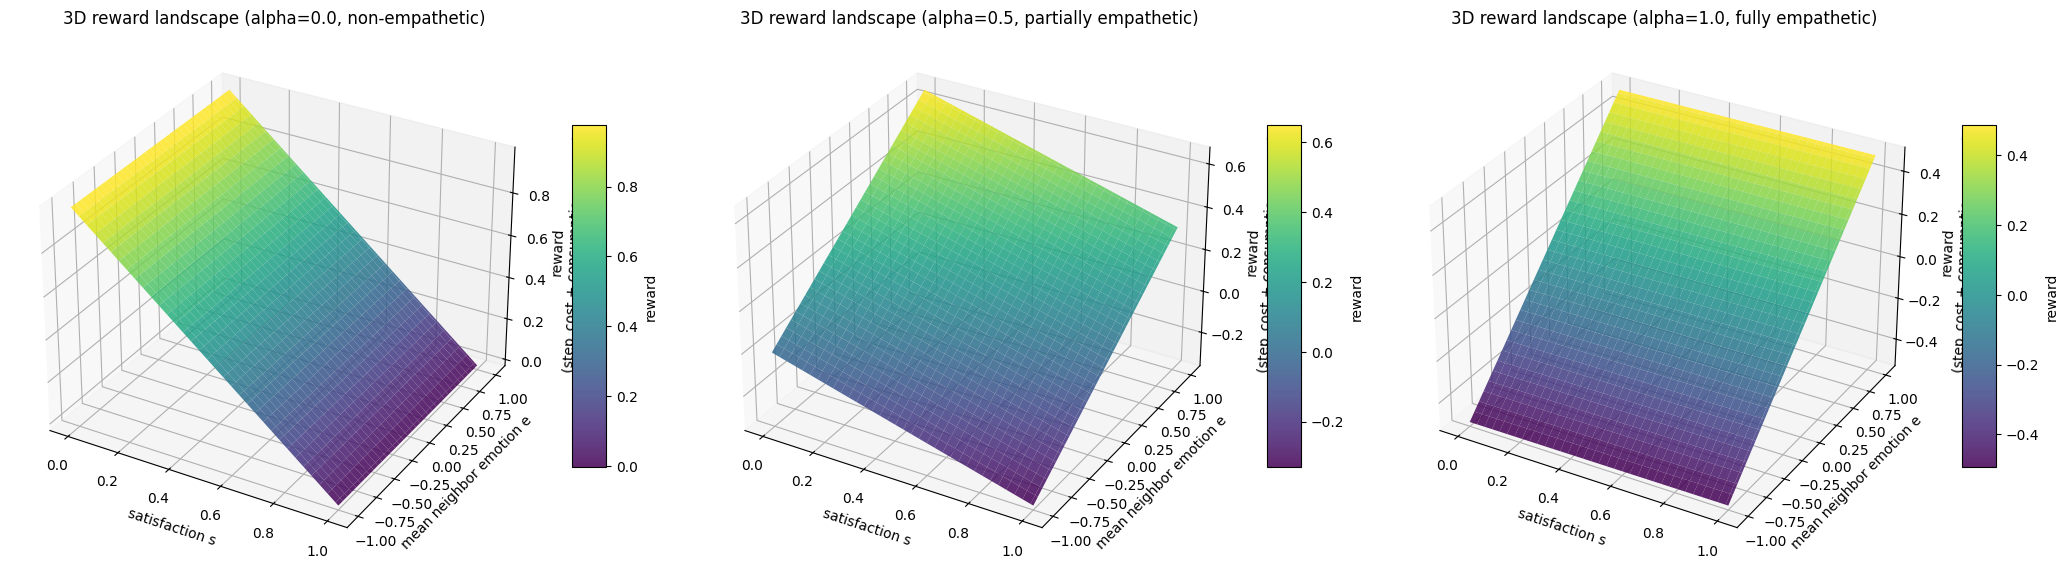

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (needed for 3D projection)

# Reuse the original reward shaping code (do NOT re-implement the formula here)
from agent_2d import EmpathicRewardCalculator

# --- Parameters (match env_2d defaults unless you change them there) ---
EXPLOIT_REWARD = 1.0
EMPATHIC_PENALTY = -1.0
STEP_COST = -0.01

# Grids
S_GRID = np.linspace(0.0, 1.0, 101)   # satisfaction s
E_GRID = np.linspace(-1.0, 1.0, 101)  # mean neighbor emotion e
S, E = np.meshgrid(S_GRID, E_GRID, indexing='xy')


class _DummyAgent:
    """Minimal agent shim to call EmpathicRewardCalculator without touching agent/env code."""

    def __init__(self):
        self._s = 0.0
        self._e = 0.0

    def set_satisfaction(self, s: float):
        self._s = float(s)

    def set_emotion(self, e: float):
        self._e = float(e)

    def get_satisfaction(self) -> float:
        return self._s

    def get_emotion(self) -> float:
        return self._e


def _consumption_reward_grid(alpha: float) -> np.ndarray:
    """Return the consumption reward term r_consume(s,e) grid for a fixed alpha.

    This calls the original `EmpathicRewardCalculator` from `agent_2d.py`.
    """

    calc = EmpathicRewardCalculator(
        exploit_reward=EXPLOIT_REWARD,
        empathic_penalty=EMPATHIC_PENALTY,
        empathy_alpha=float(alpha),
    )

    # We always pass a neighbor list of length 1 so we are plotting the "with neighbors" case.
    # Create fresh agent objects for each call to avoid closure/mutable object issues with np.vectorize
    def _reward_scalar(s, e):
        self_agent = _DummyAgent()
        neighbor = _DummyAgent()
        self_agent.set_satisfaction(s)
        neighbor.set_emotion(e)
        return calc.consumption_reward(self_agent=self_agent, nearby_agents=[neighbor])

    return np.vectorize(_reward_scalar)(S, E).astype(np.float32)


def _total_reward_grid(alpha: float) -> np.ndarray:
    # Total reward on a consumption step in the env: step_cost + consumption_reward
    return (STEP_COST + _consumption_reward_grid(alpha)).astype(np.float32)


fig = plt.figure(figsize=(21, 6))

# Plot for empathy = 0 (alpha = 0)
alpha0 = 0.0
R0 = _total_reward_grid(alpha0)
ax0 = fig.add_subplot(1, 3, 1, projection='3d')
surf0 = ax0.plot_surface(S, E, R0, cmap='viridis', edgecolor='none', alpha=0.85)
ax0.set_title("3D reward landscape (alpha=0.0, non-empathetic)")
ax0.set_xlabel('satisfaction s')
ax0.set_ylabel('mean neighbor emotion e')
ax0.set_zlabel('reward\n(step_cost + consumption_reward)')
fig.colorbar(surf0, ax=ax0, shrink=0.6, aspect=10, label='reward')

# Plot for empathy = 0.5 (alpha = 0.5)
alpha05 = 0.5
R05 = _total_reward_grid(alpha05)
ax05 = fig.add_subplot(1, 3, 2, projection='3d')
surf05 = ax05.plot_surface(S, E, R05, cmap='viridis', edgecolor='none', alpha=0.85)
ax05.set_title("3D reward landscape (alpha=0.5, partially empathetic)")
ax05.set_xlabel('satisfaction s')
ax05.set_ylabel('mean neighbor emotion e')
ax05.set_zlabel('reward\n(step_cost + consumption_reward)')
fig.colorbar(surf05, ax=ax05, shrink=0.6, aspect=10, label='reward')

# Plot for empathy = 1 (alpha = 1)
alpha1 = 1.0
R1 = _total_reward_grid(alpha1)
ax1 = fig.add_subplot(1, 3, 3, projection='3d')
surf1 = ax1.plot_surface(S, E, R1, cmap='viridis', edgecolor='none', alpha=0.85)
ax1.set_title("3D reward landscape (alpha=1.0, fully empathetic)")
ax1.set_xlabel('satisfaction s')
ax1.set_ylabel('mean neighbor emotion e')
ax1.set_zlabel('reward\n(step_cost + consumption_reward)')
fig.colorbar(surf1, ax=ax1, shrink=0.6, aspect=10, label='reward')

plt.tight_layout()
plt.show()

